# 04. Spatial distribution around genes

Describe genotype–environment association (GEA) signals and genomic features around transcription start sites (TSSs) and transcription termination sites (TTSs). Use individual flowering-time genes to illustrate relative association signal intensity (RASI), then examine the spatial profiles of genes with the strongest GEA signals.



### Environment setup


In [36]:
import warnings
warnings.filterwarnings('ignore')

import os
import socket
import sys
import yaml
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

with open('config/project.yaml') as handle:
    project_config = yaml.safe_load(handle)
project_dir = project_config['remote']['project_root']
if os.path.realpath(os.getcwd()) != os.path.realpath(project_dir):
    raise ValueError(f'Working directory {os.getcwd()} must match configured project root {project_dir}.')
if project_dir not in sys.path:
    sys.path.insert(0, project_dir)
data_dir = f'{project_dir}/data'
source_dir = f'{data_dir}/source'
results_dir = f'{data_dir}/results'
run_dir = f'{project_dir}/run'
sd_dir = f'{results_dir}/spatial_distribution'
gwas_dir = f'{results_dir}/gwas'

from src.plot import set_plot_style
set_plot_style()
print(f'Host: {socket.gethostname()}')
print(f'Working directory: {os.getcwd()}')
print(f'Python: {sys.executable}')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Host: rock01.local
Working directory: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum
Python: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base/bin/python


## 1. Relative association signal intensity

Summarize valid raw P values in 500 bp windows with a 10 bp step across 10 kb flanks of each TSS or TTS. Define relative association signal intensity (RASI) as the ratio of the transformed window and regional 25th percentiles:

$$\mathrm{RASI}_w=\frac{-\log_{10}[Q_{25}(P_i\mid i\in w)]}{-\log_{10}[Q_{25}(P_i\mid i\in R)]}.$$

Here $w$ is a window and $R$ is the full anchor region. Percentiles and variant counts exclude nonfinite P values. Windows with fewer than four valid variants use the regional percentile, giving RASI=1, and regions with fewer than four valid variants have RASI=1 throughout. Association results use genome-wide variants with MAF ≥0.05 and heterozygosity ≤0.05.



RASI >1 indicates stronger window GEA signals than the regional reference, and RASI <1 indicates weaker signals. Compare gene-set profiles with random-gene distributions to assess enrichment or depletion. The ratio is undefined when the transformed regional percentile is zero.



### 1.1 Examples at ELF3 and LWD1

Use growing season length signals at ELF3 and LWD1 to illustrate RASI around TSS and TTS.



In [37]:
from src.gene_profiles import prepare_rasi_examples, plot_rasi_example

gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
env_id = 'gsl'
env_description = 'Growing Season Length'
gwas_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gene_configs = [
    dict(gene_id='Sobic.009G257300.v5.1', gene_name='ELF3'),
    dict(gene_id='Sobic.004G161701.v5.1', gene_name='LWD1'),
]
flank = 10000
bin_size = 500
step = 10
min_variants = 4
force_recompute = False
example_dir = f'{sd_dir}/rasi_examples'
example_prefixes = {
    gene['gene_name']: f"{example_dir}/{gene['gene_id']}.{env_id}.rasi"
    for gene in gene_configs
}


In [38]:
rasi_examples = prepare_rasi_examples(
    gff_file, gwas_h5, gene_configs, example_dir,
    env_id=env_id, env_description=env_description,
    flank=flank, bin_size=bin_size, step=step,
    min_variants=min_variants, force_recompute=force_recompute,
)
rasi_examples['summaries'][['GENE_NAME', 'ANCHOR', 'N_VARIANTS', 'REGION_P_Q25', 'REGION_SIGNAL']]


[03:51:05] Preparing 0 RASI examples


RASI examples: 100%|██████████| 2/2 [00:00<00:00,  3.20it/s]

Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/rasi_examples/Sobic.009G257300.v5.1.gsl.rasi.summary.csv.gz; explicit recomputation is required after input/parameter changes.
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/rasi_examples/Sobic.004G161701.v5.1.gsl.rasi.summary.csv.gz; explicit recomputation is required after input/parameter changes.


,GENE_NAME,ANCHOR,N_VARIANTS,REGION_P_Q25,REGION_SIGNAL
0,ELF3,TSS,116,0.036630,1.436167
1,ELF3,TTS,132,0.049701,1.303634
2,LWD1,TSS,117,0.033680,1.472631
3,LWD1,TTS,95,0.033680,1.472631


In [39]:
windows = pd.read_csv(f"{example_prefixes['ELF3']}.windows.csv.gz")
example_window = windows.loc[windows['RASI'].notna()].head(1).copy()
example_window['RASI_FROM_PERCENTILE'] = example_window['WINDOW_SIGNAL'] / example_window['REGION_SIGNAL']
example_window[['ANCHOR', 'RELATIVE_CENTER', 'N_VARIANTS', 'WINDOW_SIGNAL', 'REGION_SIGNAL', 'RASI_FROM_PERCENTILE']]


,ANCHOR,RELATIVE_CENTER,N_VARIANTS,WINDOW_SIGNAL,REGION_SIGNAL,RASI_FROM_PERCENTILE
0,TSS,-9749.0,2,1.436167,1.436167,1.0


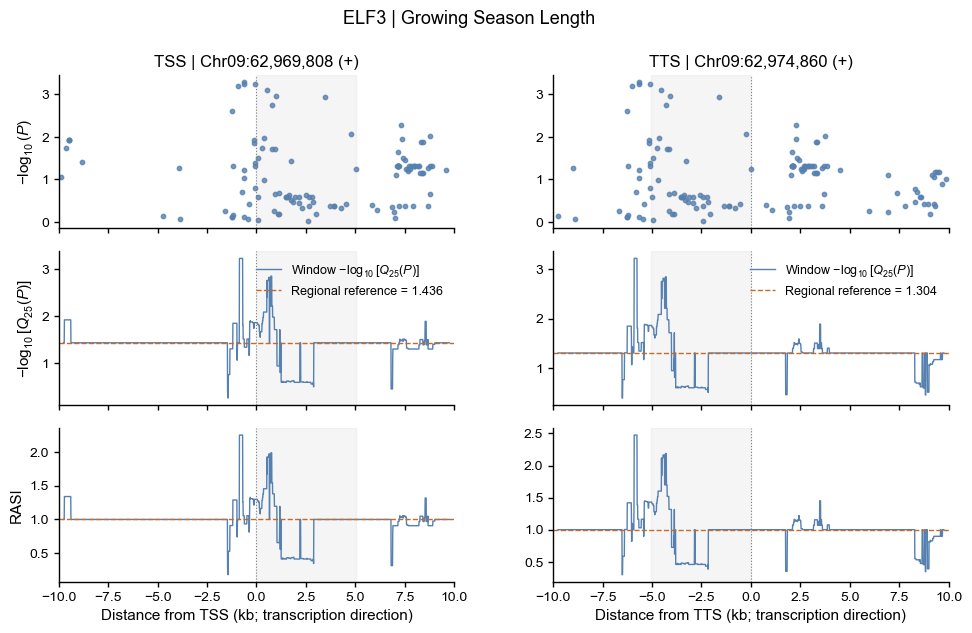

In [40]:
prefix = example_prefixes['ELF3']
elf3_rasi_plot = plot_rasi_example(
    f'{prefix}.sites.csv.gz', f'{prefix}.windows.csv.gz', f'{prefix}.summary.csv.gz',
    f'{prefix}.example', figsize=(10, 6.5),
)
plt.show()


**Figure 1. Relative association signal intensity at `ELF3` for growing season length.** Columns show TSS and TTS regions aligned in transcription direction. From top to bottom, panels show variant −log10(P), the transformed window P-value quartile alongside its regional reference, and RASI. Blue points and curves show the observed signals, orange dashed lines mark the regional reference and RASI=1, and gray shading marks the gene body. Vertical dotted lines mark the anchors.



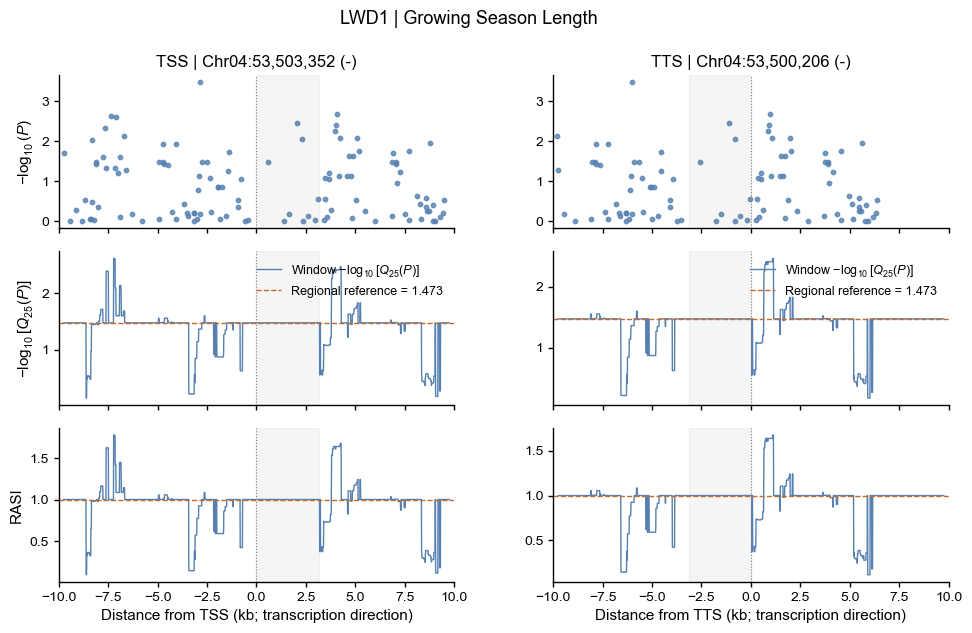

In [41]:
prefix = example_prefixes['LWD1']
lwd1_rasi_plot = plot_rasi_example(
    f'{prefix}.sites.csv.gz', f'{prefix}.windows.csv.gz', f'{prefix}.summary.csv.gz',
    f'{prefix}.example', figsize=(10, 6.5),
)
plt.show()


**Figure 2. Relative association signal intensity at `LWD1` for growing season length.** Columns show TSS and TTS regions aligned in transcription direction. From top to bottom, panels show variant −log10(P), the transformed window P-value quartile alongside its regional reference, and RASI. Blue points and curves show the observed signals, orange dashed lines mark the regional reference and RASI=1, and gray shading marks the gene body. Vertical dotted lines mark the anchors.



## 2. Promoter mutation effects

Use barcode-level promoter mutagenesis data for PsbS, Raf1 and SBPase from Groover et al. (2026) to estimate individual mutation effects and their spatial distribution. Fit an additive linear model with an intercept to log₂ expression read ratios to separate effects in constructs carrying multiple mutations, using reliably mapped barcodes with valid expression and excluding forbidden mutations.



In [42]:
from src.mutant_effects import (
    prepare_mutation_effects, prepare_mutation_profiles,
    plot_mean_mutation_effects, plot_combined_high_effect_index,
)

mutation_source_dir = f'{source_dir}/Groover_2026_nbt'
mutation_results_dir = f'{results_dir}/mutant_effects'
gene_csvs = {
    'SBPase': f'{mutation_source_dir}/3A_sorghum.csv.gz',
    'Raf1': f'{mutation_source_dir}/3B_sorghum.csv.gz',
    'PsbS': f'{mutation_source_dir}/3C_sorghum.csv.gz',
}
min_barcodes = 1
atol = 1e-8
btol = 1e-8
iter_lim = 3000
force_recompute = False
mean_xlim = (-2000, 250)
mean_window_bp = 100
mean_step_bp = 10
min_obs = 5
index_xlim = (-5000, 1000)
index_window_bp = 500
index_step_bp = 10
high_effect_quantile = 0.95
alpha = 0.5
mean_windows_csv = f'{mutation_results_dir}/mean_mutation_effects.windows.csv.gz'
combined_index_csv = f'{mutation_results_dir}/combined_high_effect_index.csv'
mean_figure_prefix = f'{mutation_results_dir}/mean_mutation_effects'
index_figure_prefix = f'{mutation_results_dir}/combined_high_effect_index'



In [43]:
mutation_effects = prepare_mutation_effects(
    gene_csvs, mutation_results_dir, min_barcodes=min_barcodes,
    atol=atol, btol=btol, iter_lim=iter_lim, force_recompute=force_recompute,
)
mutation_effects['fit_summary'][['gene', 'kept_barcodes', 'mutations', 'mapped_to_tss', 'lsqr_istop', 'lsqr_iterations']]


Single-mutation effects: 100%|██████████| 3/3 [00:00<00:00, 38.12it/s]

[03:51:20] Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/mutant_effects/SBPase.mutation_effects.csv.gz; input-content changes require force_recompute=True.
[03:51:20] Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/mutant_effects/Raf1.mutation_effects.csv.gz; input-content changes require force_recompute=True.
[03:51:20] Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/mutant_effects/PsbS.mutation_effects.csv.gz; input-content changes require force_recompute=True.


,gene,kept_barcodes,mutations,mapped_to_tss,lsqr_istop,lsqr_iterations
0,SBPase,95793,30186,30186,2,1524
1,Raf1,30015,15865,15865,2,1761
2,PsbS,46195,20847,20847,2,1196


### 2.1 Mean mutation-effect profiles

Summarize inferred mutation effects in 100 bp windows with a 10 bp step, retaining gene windows with at least five mutations.



In [44]:
mutation_profiles = prepare_mutation_profiles(
    mutation_effects['effect_files'], mutation_results_dir,
    mean_xlim=mean_xlim, mean_window_bp=mean_window_bp, mean_step_bp=mean_step_bp,
    min_obs=min_obs, index_xlim=index_xlim, index_window_bp=index_window_bp,
    index_step_bp=index_step_bp, high_effect_quantile=high_effect_quantile,
    alpha=alpha, force_recompute=force_recompute,
)
pd.read_csv(mutation_profiles['summary'])


[03:51:21] Reusing mutation profiles; changed effect-table contents require force_recompute=True.


,gene,mutations,high_effect_mutations,abs_effect_threshold
0,PsbS,20847,1043,0.751310
1,Raf1,15865,794,1.170788
2,SBPase,30186,1510,0.671551


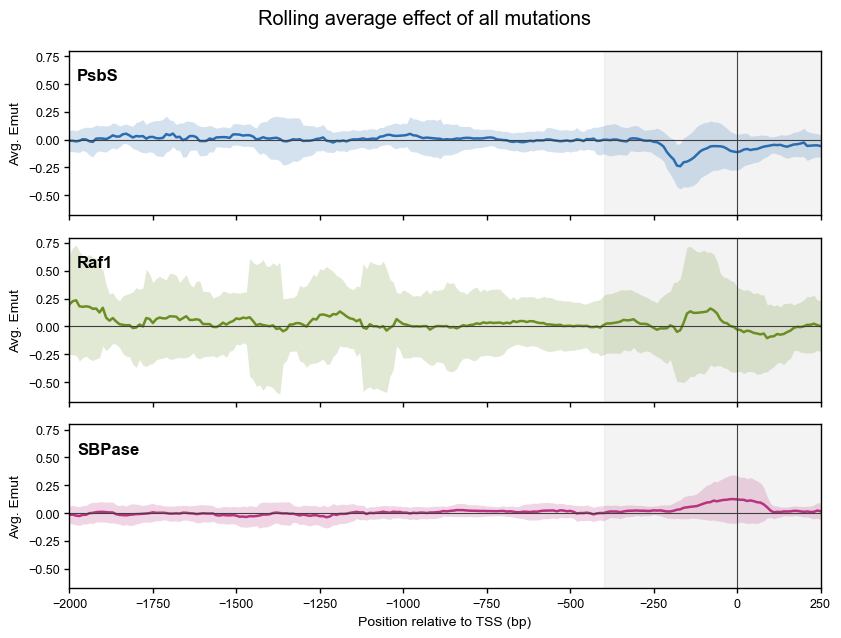

In [45]:
mean_effect_plot = plot_mean_mutation_effects(
    mean_windows_csv, mean_figure_prefix, xlim=mean_xlim,
    spread='variance', figsize=(8.5, 6.5),
)
plt.show()


**Figure 3. Spatial distribution of inferred promoter mutation effects.** Panels show PsbS, Raf1 and SBPase from top to bottom. Curves show mean inferred effects in 100 bp windows with a 10 bp step, and colored bands show mean ± variance. Positive and negative values indicate expression-increasing and expression-decreasing effects. The vertical line marks TSS, and gray shading extends from 400 bp upstream of TSS to the displayed downstream boundary.



### 2.2 High-effect mutation index

Within each gene, define high-effect mutations as the top 5% by absolute inferred effect, including threshold ties and both expression-increasing and expression-decreasing effects. Use 500 bp windows with a 10 bp step and include all mutations with valid effects and TSS positions in each gene’s background.

Pool high-effect counts $k_g$ and total counts $n_g$ across genes with at least five mutations in a window. With pseudocount $\alpha=0.5$, define the combined index as

$$I_w=\frac{(\sum_g k_g+\alpha)/(\sum_g n_g+2\alpha)}{\sum_g n_g p_g/\sum_g n_g},\qquad p_g=\frac{K_g+\alpha}{N_g+2\alpha}.$$

Here $K_g$ and $N_g$ are gene-wide high-effect and total mutation counts. Weight gene backgrounds by window mutation counts. Values above or below 1 indicate relative enrichment or depletion of high-effect mutations.



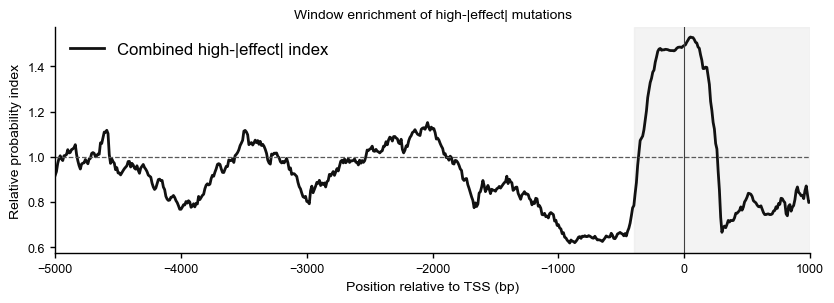

In [46]:
high_effect_plot = plot_combined_high_effect_index(
    combined_index_csv, index_figure_prefix, xlim=index_xlim, figsize=(8.5, 3.2),
)
plt.show()


**Figure 4. Spatial distribution of high-effect promoter mutations.** The black curve shows the combined relative probability index for high-effect mutations defined as the top 5% by absolute inferred effect within each of PsbS, Raf1 and SBPase in 500 bp windows with a 10 bp step. The horizontal dashed line marks the background reference of 1, and the vertical line marks TSS. Gray shading extends from 400 bp upstream of TSS to the displayed downstream boundary.



## 3. Gene-set spatial profiles

Compare genes with the strongest 5% of GEA signals with 1,000 equally sized random sets sampled without replacement within each set from the remaining eligible genes. Select a fixed number of top genes by gene P value without expanding threshold ties, and use the same random sets for every track and anchor. Their mean profiles define empirical 90% intervals (fifth–ninety-fifth percentiles).



### 3.1 Gene-centered genomic features

Summarize features around TSS and TTS in 500 bp windows with a 10 bp step, aligned in transcription direction. RASI follows the definition above.

- **Nucleotide diversity (π)** is per-base pairwise diversity across each window, using landrace genotypes without additional MAF filtering. Windows without variant records have π=0.
- **ACR and UMR coverage** is the fraction of window bases covered by the union of annotation intervals. Overlapping intervals are counted once.
- **LD** is the mean finite pairwise r² between variants in a 500 bp anchor-centered reference window and each sliding window, using genome-wide variant genotypes and excluding identical-site pairs.

For π, LD and coverage, full windows extending beyond chromosome boundaries retain missing values. LD windows without usable pairs also retain missing values.



In [47]:
from src.gene_profiles import (
    prepare_spatial_profile_database, prepare_gene_set_profiles,
    plot_gene_set_profiles, DEFAULT_PLOT_CONFIG,
)

env_ids = ['bio18', 'gsl', 'al', 'striga']
env_metadata_df = pd.read_csv(f'{source_dir}/envir_metadata.csv').set_index('env_id')
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
genome_fasta_file = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
pi_vcf_file = f'{results_dir}/landraces.vcf.gz'
acr_bed_file = f'{source_dir}/ACRs.v5.bed.gz'
umr_bed_file = f'{source_dir}/UMRs.v5.bed.gz'
profile_dir = f'{sd_dir}/gene_profiles'
profile_manifest = f'{profile_dir}/profile_database.json'
summary_dir = f'{sd_dir}/gene_set_profiles'
association_sources = {
    env: f'{gwas_dir}/{env}/{env}.gemma/{env}.gemma.gwas_df.h5' for env in env_ids
}
magma_sources = {
    env: f'{gwas_dir}/{env}/{env}.magma/{env}.magma.gwas_df.h5' for env in env_ids
}
high_effect_csv = f'{results_dir}/mutant_effects/combined_high_effect_index.csv'
flank = 10000
bin_size = 500
step = 10
min_variants = 4
threads = project_config['resources']['interactive']['cores']
ld_threads = min(4, threads)
bed_zero_based = False
exclude_self = True
min_pairs = 1
force_recompute = False



In [48]:
profile_database = prepare_spatial_profile_database(
    gff_file, association_sources, qc_vcf_file, pi_vcf_file,
    acr_bed_file, umr_bed_file, profile_dir,
    genome_fasta_file=genome_fasta_file,
    flank=flank, bin_size=bin_size, step=step, min_variants=min_variants,
    threads=threads, ld_threads=ld_threads, bed_zero_based=bed_zero_based,
    exclude_self=exclude_self, min_pairs=min_pairs, force_recompute=force_recompute,
)
profile_database


Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/gene_info.gff.h5
[03:51:34] Building spatial profiles for 32160 genes


RASI environments:  50%|█████     | 2/4 [00:00<00:00, 14.15it/s]

Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.bio18.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.bio18.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.gsl.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.gsl.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.al.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.al.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distr

RASI environments: 100%|██████████| 4/4 [00:00<00:00, 19.55it/s]

Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.striga.h5


Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.pi.unfiltered.centered.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.pi.unfiltered.centered.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.LD.centered.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.LD.centered.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.ACR.coverage.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.ACR.coverage.h5
Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adapt

{'gene_info': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/gene_info.gff.h5',
 'rasi': {'bio18': {'TSS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.bio18.h5',
   'TTS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.bio18.h5'},
  'gsl': {'TSS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.gsl.h5',
   'TTS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TTS.RASI.gsl.h5'},
  'al': {'TSS': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_profiles/TSS.RASI.al.h5',
   'TTS': '/lustre/home/dobby/Work/Project

### 3.2 Spatial profiles of genes with strong GEA signals

Use genes with valid gene-level GEA results and available spatial profiles. Average each track across the selected top genes, excluding missing values at each position, and compare these means with equal-size random-gene sets. Display 5.5 kb flanks of each anchor alongside the independent TSS promoter mutation index.



In [49]:
top_gene_quantile = 0.05
random_num = 1000
seed = 42
plot_xlim = (-5500, 5500)
ci_percentiles = (5, 95)
random_batch_size = 8
summary_prefixes = {env: f'{summary_dir}/{env}.gene_set_profiles' for env in env_ids}
figure_prefixes = {env: f'{sd_dir}/{env}.gene_profiles' for env in env_ids}



In [50]:
from tqdm.auto import tqdm

for env_id in tqdm(env_ids, desc='Gene-set spatial summaries'):
    summary_files = prepare_gene_set_profiles(
        profile_manifest, env_id, magma_sources[env_id], high_effect_csv,
        summary_prefixes[env_id], top_gene_quantile=top_gene_quantile,
        random_num=random_num, seed=seed, plot_xlim=plot_xlim,
        ci_percentiles=ci_percentiles, random_batch_size=random_batch_size,
        force_recompute=force_recompute,
    )
    print(summary_files)



Gene-set spatial summaries: 100%|██████████| 4/4 [00:00<00:00, 99.92it/s]

Reusing /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles; input-content changes require force_recompute=True.
{'profiles': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles.profiles.csv.gz', 'selection': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles.genes.csv.gz', 'gene_info': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles.top_gene_info.csv.gz', 'metadata': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gene_set_profiles/bio18.gene_set_profiles.metadata.json'}
Reusing /lustre/home/dobby/Work/Project/functional-g

Display the spatial profiles for the four key environmental variables



In [51]:
plot_config = dict(DEFAULT_PLOT_CONFIG)
plot_config.update(
    fig_size=(11, 6.5), track_order=['LD', 'pi', 'ACR', 'UMR', 'high_effect_index'],
    show_fig=False, save_fig=False, grid_hspace=0.25, gene_bar_y=0.675, utr_bar_y=0.645
)



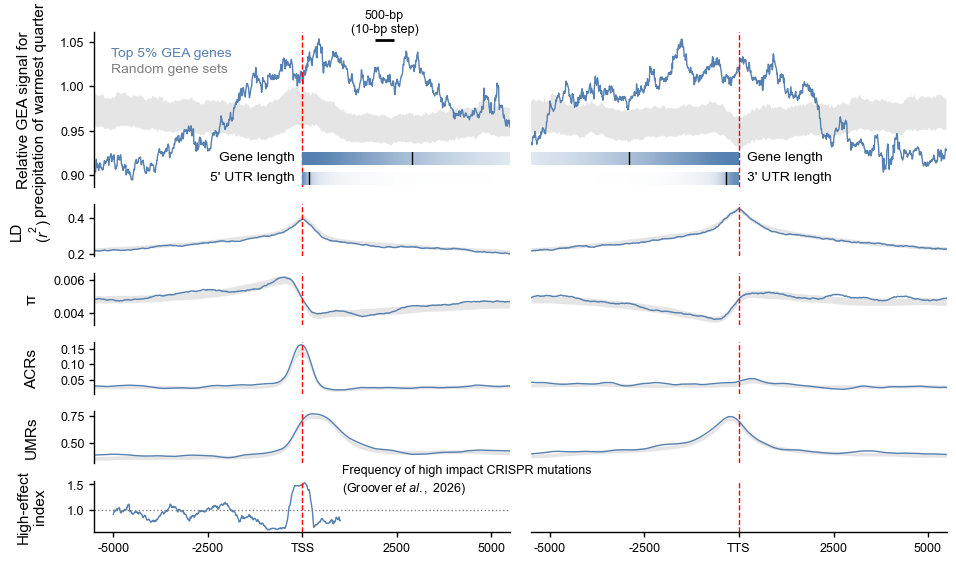

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/bio18.gene_profiles.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/bio18.gene_profiles.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/bio18.gene_profiles.csv.gz'}


In [52]:
env_id = 'bio18'
bio18_profile_plot = plot_gene_set_profiles(
    summary_prefixes[env_id], env_metadata_df.loc[env_id, 'description'],
    figure_prefixes[env_id], config=plot_config,
)
plt.show()
print(bio18_profile_plot['files'])


**Figure 5. Spatial distribution of envGWAS signals around genes associated with precipitation of the warmest quarter.** Profiles are shown around both ends of the top 5% of genes with the strongest GEA signals for precipitation of the warmest quarter. The x-axis indicates distance (bp) from the transcription start site (TSS, left) or transcription termination site (TTS, right). Bars labeled gene length and 5′/3′ UTR length show their distributions across selected genes, with darker shading indicating a higher proportion of genes extending to that position and black vertical ticks marking median lengths. The dark-blue curve shows the relative enrichment of envGWAS signals, calculated as the ratio of −log10-transformed first quartiles (Q1) of raw P values within sliding windows (500 bp window, 10 bp step) to the corresponding transformed Q1 across the entire ±10 kb region around TSS or TTS. The gray band denotes the empirical 90% range (fifth–ninety-fifth percentiles) from 1,000 equal-size random-gene sets. The LD track shows mean pairwise r² between variants in each sliding window and those in the 500 bp reference window centered on TSS or TTS. ACR and UMR tracks show the proportion of bases overlapping each feature, and π shows nucleotide diversity in the same windows. The bottom TSS track shows the enrichment index of high-effect CRISPR-accessible promoter mutations from Groover et al. (2026), with the dotted line at index=1 indicating no enrichment.



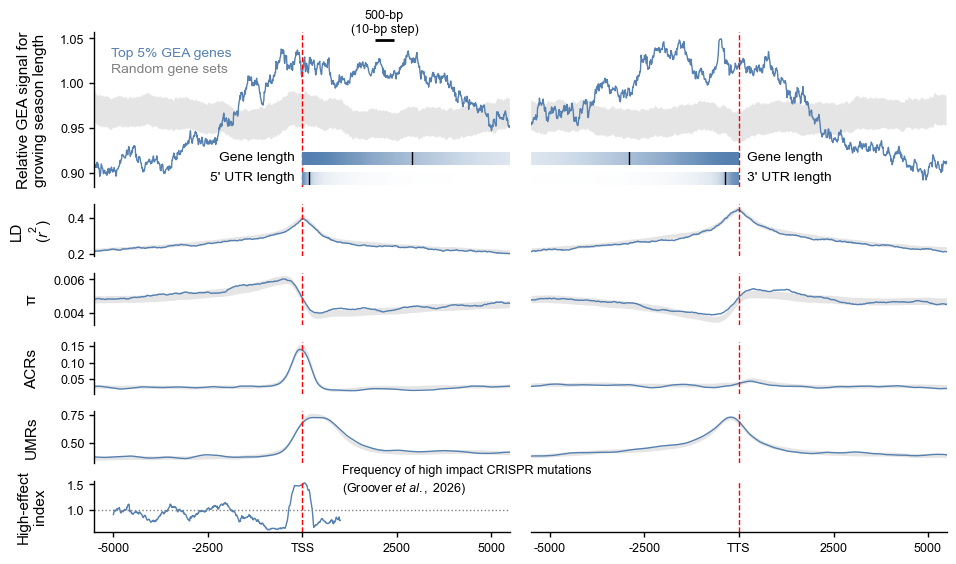

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gsl.gene_profiles.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gsl.gene_profiles.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/gsl.gene_profiles.csv.gz'}


In [53]:
env_id = 'gsl'
gsl_profile_plot = plot_gene_set_profiles(
    summary_prefixes[env_id], env_metadata_df.loc[env_id, 'description'],
    figure_prefixes[env_id], config=plot_config,
)
plt.show()
print(gsl_profile_plot['files'])


**Figure 6. Spatial distribution of envGWAS signals around genes associated with growing season length.** Profiles are shown around both ends of the top 5% of genes with the strongest GEA signals for growing season length. The x-axis indicates distance (bp) from the transcription start site (TSS, left) or transcription termination site (TTS, right). Bars labeled gene length and 5′/3′ UTR length show their distributions across selected genes, with darker shading indicating a higher proportion of genes extending to that position and black vertical ticks marking median lengths. The dark-blue curve shows the relative enrichment of envGWAS signals, calculated as the ratio of −log10-transformed first quartiles (Q1) of raw P values within sliding windows (500 bp window, 10 bp step) to the corresponding transformed Q1 across the entire ±10 kb region around TSS or TTS. The gray band denotes the empirical 90% range (fifth–ninety-fifth percentiles) from 1,000 equal-size random-gene sets. The LD track shows mean pairwise r² between variants in each sliding window and those in the 500 bp reference window centered on TSS or TTS. ACR and UMR tracks show the proportion of bases overlapping each feature, and π shows nucleotide diversity in the same windows. The bottom TSS track shows the enrichment index of high-effect CRISPR-accessible promoter mutations from Groover et al. (2026), with the dotted line at index=1 indicating no enrichment.



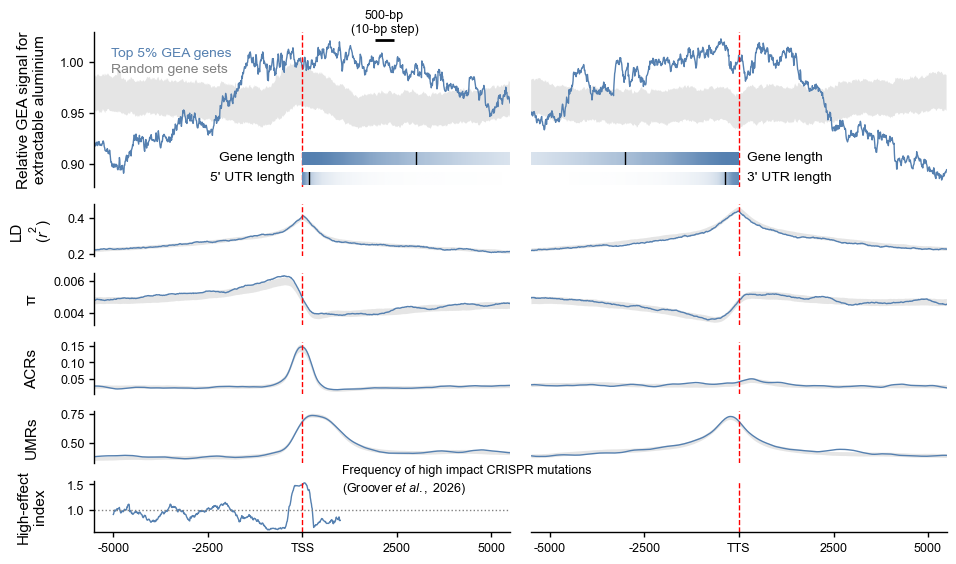

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/al.gene_profiles.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/al.gene_profiles.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/al.gene_profiles.csv.gz'}


In [54]:
env_id = 'al'
al_profile_plot = plot_gene_set_profiles(
    summary_prefixes[env_id], env_metadata_df.loc[env_id, 'description'],
    figure_prefixes[env_id], config=plot_config,
)
plt.show()
print(al_profile_plot['files'])


**Figure 7. Spatial distribution of envGWAS signals around genes associated with extractable aluminium.** Profiles are shown around both ends of the top 5% of genes with the strongest GEA signals for extractable aluminium. The x-axis indicates distance (bp) from the transcription start site (TSS, left) or transcription termination site (TTS, right). Bars labeled gene length and 5′/3′ UTR length show their distributions across selected genes, with darker shading indicating a higher proportion of genes extending to that position and black vertical ticks marking median lengths. The dark-blue curve shows the relative enrichment of envGWAS signals, calculated as the ratio of −log10-transformed first quartiles (Q1) of raw P values within sliding windows (500 bp window, 10 bp step) to the corresponding transformed Q1 across the entire ±10 kb region around TSS or TTS. The gray band denotes the empirical 90% range (fifth–ninety-fifth percentiles) from 1,000 equal-size random-gene sets. The LD track shows mean pairwise r² between variants in each sliding window and those in the 500 bp reference window centered on TSS or TTS. ACR and UMR tracks show the proportion of bases overlapping each feature, and π shows nucleotide diversity in the same windows. The bottom TSS track shows the enrichment index of high-effect CRISPR-accessible promoter mutations from Groover et al. (2026), with the dotted line at index=1 indicating no enrichment.



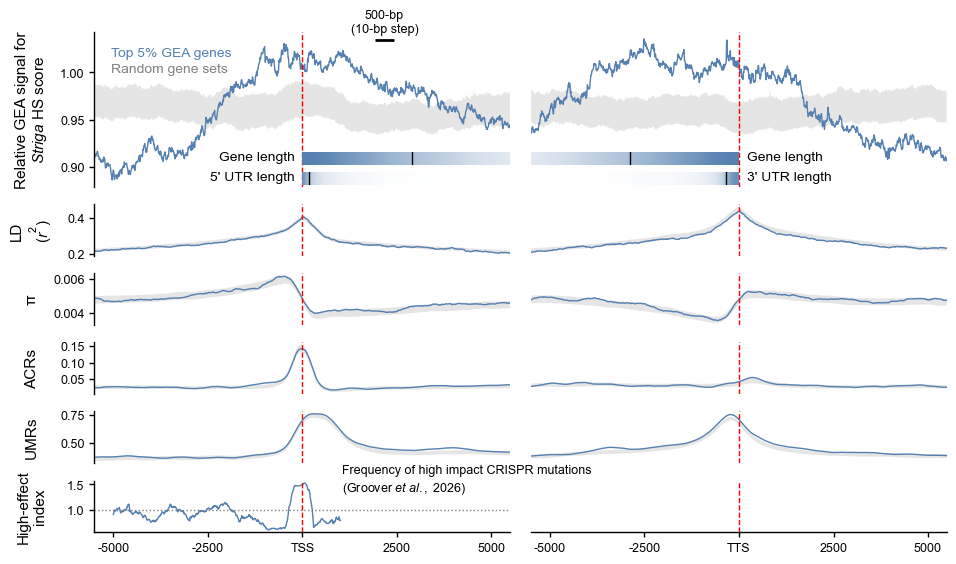

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/striga.gene_profiles.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/striga.gene_profiles.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/spatial_distribution/striga.gene_profiles.csv.gz'}


In [55]:
env_id = 'striga'
striga_profile_plot = plot_gene_set_profiles(
    summary_prefixes[env_id], env_metadata_df.loc[env_id, 'description'],
    figure_prefixes[env_id], config=plot_config,
)
plt.show()
print(striga_profile_plot['files'])


**Figure 8. Spatial distribution of envGWAS signals around genes associated with Striga HS score.** Profiles are shown around both ends of the top 5% of genes with the strongest GEA signals for Striga HS score. The x-axis indicates distance (bp) from the transcription start site (TSS, left) or transcription termination site (TTS, right). Bars labeled gene length and 5′/3′ UTR length show their distributions across selected genes, with darker shading indicating a higher proportion of genes extending to that position and black vertical ticks marking median lengths. The dark-blue curve shows the relative enrichment of envGWAS signals, calculated as the ratio of −log10-transformed first quartiles (Q1) of raw P values within sliding windows (500 bp window, 10 bp step) to the corresponding transformed Q1 across the entire ±10 kb region around TSS or TTS. The gray band denotes the empirical 90% range (fifth–ninety-fifth percentiles) from 1,000 equal-size random-gene sets. The LD track shows mean pairwise r² between variants in each sliding window and those in the 500 bp reference window centered on TSS or TTS. ACR and UMR tracks show the proportion of bases overlapping each feature, and π shows nucleotide diversity in the same windows. The bottom TSS track shows the enrichment index of high-effect CRISPR-accessible promoter mutations from Groover et al. (2026), with the dotted line at index=1 indicating no enrichment.

